## Lab - EDA Univariate
### Ironhack - Data Analytics
### Name: Bryan Calderon



In [ ]:
# Install dependencies as needed:
#!pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
print("Path to dataset files:", path)

100%|██████████| 117M/117M [00:23<00:00, 5.20MB/s] 

Extracting files...


Path to dataset files: C:\Users\bryan\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [25]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv", encoding="latin1")
df.describe(include ="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
uid,2443651.0,NaN,NaN,NaN,1370545.345231,816056.169852,1.0,658921.5,1349029.0,2060685.5,2828593.0
asin,2443651,2222742,B083L94P36,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,2443651,2077591,OYhmc Portable Pedal Exerc,723,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stars,2443651.0,NaN,NaN,NaN,2.152836,2.194865,0.0,0.0,0.0,4.4,5.0
reviews,2443651.0,NaN,NaN,NaN,480.627757,5944.124151,0.0,0.0,0.0,59.0,1356658.0
price,2443651.0,NaN,NaN,NaN,89.243809,345.608862,0.0,9.99,19.09,45.99,100000.0
isBestSeller,2443651,2,False,2435671,NaN,NaN,NaN,NaN,NaN,NaN,NaN
boughtInLastMonth,2443651.0,NaN,NaN,NaN,25.896988,240.483727,0.0,0.0,0.0,0.0,50000.0
category,2443651,296,Sports & Outdoors,836265,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
## Fast cleaning and corrections
df.isna().sum()
df.duplicated().sum()
## No duplicates and no na values

np.int64(0)

## Amazon UK Product Analysis – Univariate EDA Report

Objective

The objective of this analysis is to explore product listings on Amazon UK to understand patterns in product categories, pricing, and customer ratings. The goal is to extract insights that can support better business decisions regarding pricing strategies, competition, and customer behavior.

#### Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

##### 1. Frequency Tables:

* Generate a frequency table for the product category.
* Which are the top 5 most listed product categories?

In [44]:
category_freq = df["category"].value_counts() ## Generating the frequency table
top_5_categories_df = category_freq.reset_index() 
top_5_categories_df.columns = ["Category", "Count"] ## Selecting Variables or Columns
top_5_categories_df.head(5)

,Category,Count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


##### 2. Visualizations:

* Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
* For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64


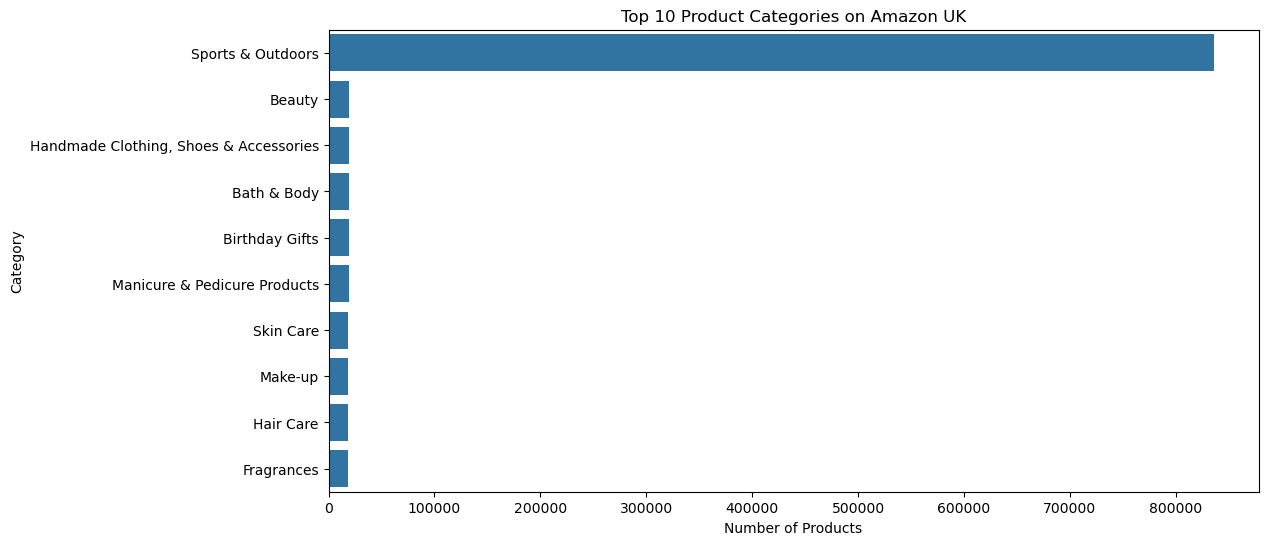

In [47]:
## Selecting only 10 categories
top_10 = df["category"].value_counts().head(10)
print(top_10)

## Generating the figure
plt.figure(figsize=(12,6))
sns.barplot(x=top_10.values, y=top_10.index)

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Number of Products")
plt.ylabel("Category")

plt.show()

##### Conclusion 1: The most popular product category on Amazon UK is Sports & Outdoors, which dominates the listings by a large margin. All other categories, such as Beauty and Bath & Body, have significantly fewer listings and are relatively similar in size.This indicates a highly concentrated market, with strong competition in the leading category.



#### Part 2: Delving into Product Pricing

Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

##### 1. Measures of Centrality:

* Calculate the mean, median, and mode for the price of products.
* What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [ ]:
stats_price = df["price"].describe() ## This solutions does not show the mode! :)

price_mean = df["price"].mean() # Mean
price_median = df["price"].median() # Median
price_mode = df["price"].mode()[0] # Mode

print(F"mean =", price_mean)
print(F"median =", price_median)
print(F"mode =", price_mode)

mean = 89.24380943923661
median = 19.09
mode = 9.99


The average product price is £89.24, while the median price is significantly lower at £19.09, and the most common price (mode) is £9.99. This indicates that most products are priced at lower values, but a small number of very expensive items increase the overall average. Therefore, product prices are highly skewed, with a concentration in the lower price range and a few high-price outliers.

##### 2. Measures of Dispersion:

* Determine the variance, standard deviation, range, and interquartile range for product price.
* How varied are the product prices? Are there any indicators of a significant spread in prices?

In [ ]:
print(stats_price)

price_range = df["price"].max() - df["price"].min()
print(f"Range price =",  price_range)

price_iqr = 45.99 - 9.99  # Interquartile Range (IQR)
print(f"Interquartile range =", price_iqr)

price_variance = df["price"].var()
print(f"Price variance =", price_variance)

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64
Range price = 100000.0
Interquartile range = 36.0
price variance = 119445.48532256528


Product prices show a high level of variability. The standard deviation is £345.61, and the range is extremely large (£0 to £100,000), indicating a wide spread in prices.

However, the interquartile range is much smaller (£36), meaning that most products are concentrated between £9.99 and £45.99.

This suggests that while most products are priced in a relatively narrow and affordable range, a few very expensive items create a significant spread in the data.


##### 3. Visualizations:

* Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
* Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

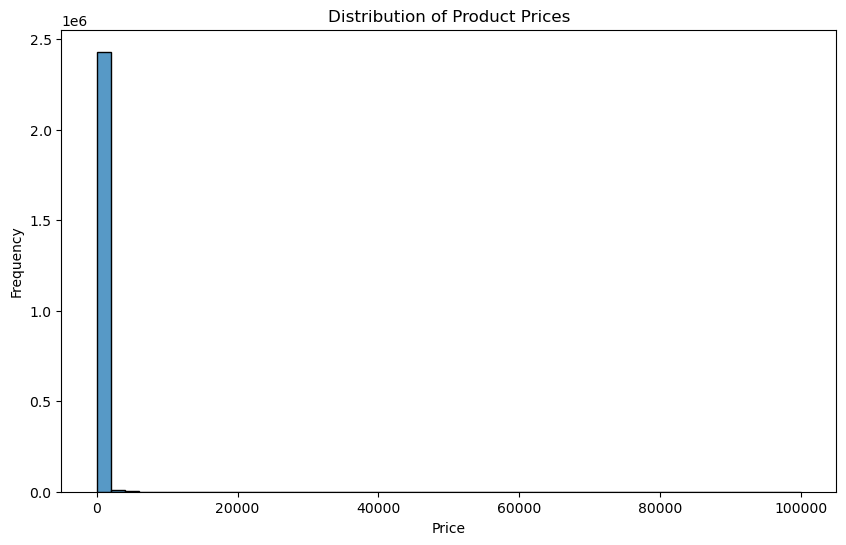

In [63]:
plt.figure(figsize=(10,6))
sns.histplot(df["price"], bins=50)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

The histogram is difficult to interpret because almost all products are concentrated at very low prices, while a few extremely high-priced products stretch the scale up to £100,000.

This issue can be resolved by filtering the data. For example by filtering price lower than £100 Check below:

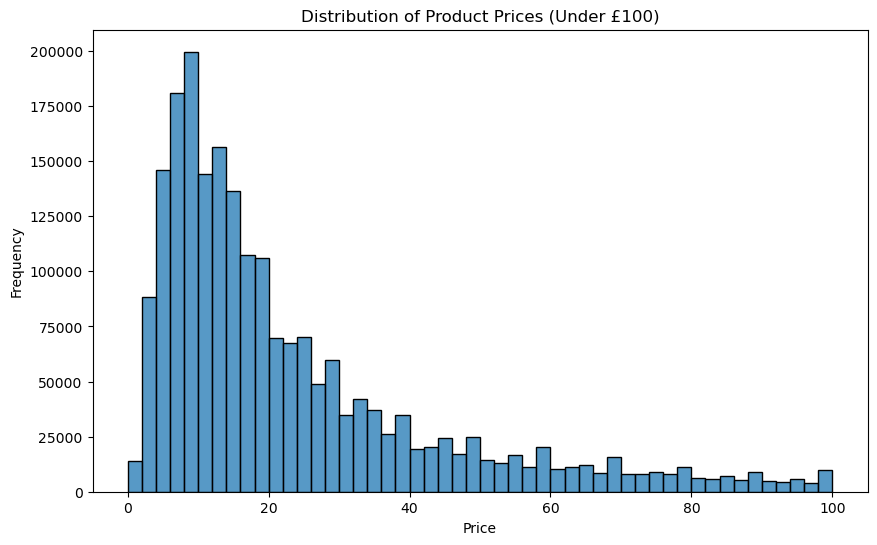

In [64]:
df_filtered = df[df["price"] <= 100]
plt.figure(figsize=(10,6))
sns.histplot(df_filtered["price"], bins=50)

plt.title("Distribution of Product Prices (Under £100)")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

The distribution is right-skewed, meaning that lower-priced products are much more common, while higher prices become progressively less frequent.

Note: A similar situation happens with the box plot. So it is better to filter the data on this chart as well. See below:

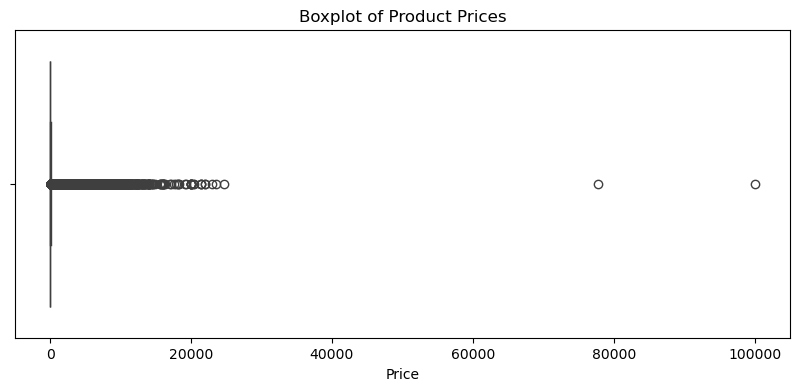

In [65]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df["price"])

plt.title("Boxplot of Product Prices")
plt.xlabel("Price")

plt.show()

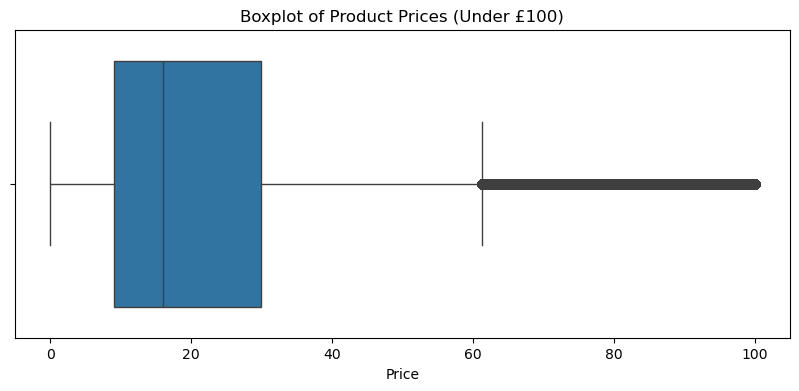

In [66]:
# Plot
plt.figure(figsize=(10,4))
sns.boxplot(x=df_filtered["price"])

plt.title("Boxplot of Product Prices (Under £100)")
plt.xlabel("Price")

plt.show()

The original boxplot shows a large number of extreme outliers, with some products priced up to £100,000, which heavily distort the visualization and compress the majority of the data.

After filtering prices below £100, the boxplot becomes much clearer. It shows that most products are concentrated between approximately £10 and £50, with the median around £19.

##### Conclusion 2: Amazon UK is largely a low-price market, but includes a small number of premium products that significantly affect overall statistics.

#### Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

##### 1. Measures of Centrality:

* Calculate the mean, median, and mode for the rating of products.
* How do customers generally rate products? Is there a common trend?

In [ ]:
rating_mean = df["stars"].mean() # Mean
rating_median = df["stars"].median()  # Median
rating_mode = df["stars"].mode()[0] # Mode

print(f"Rating mean", rating_mean)
print(f"Rating median", rating_median)
print(f"Rating mede", rating_mode)

df["stars"].value_counts().head(5) # Here we can check that 0.0 is the most frequent rating


Rating mean 2.152836472966066
Rating median 0.0
Rating mede 0.0


stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
Name: count, dtype: int64

The initial analysis showed a mean rating of 2.15 and a median of 0, which indicates that many products have no ratings. Since a rating of zero likely represents missing reviews rather than actual customer feedback, I excluded from the analysis.

In [75]:
df_ratings = df[df["stars"] > 0]
rating_mean = df_ratings["stars"].mean()
rating_median = df_ratings["stars"].median()
rating_mode = df_ratings["stars"].mode()[0]

print(f"Rating mean", rating_mean)
print(f"Rating median", rating_median)
print(f"Rating mede", rating_mode)

Rating mean 4.319160762226911
Rating median 4.4
Rating mede 4.5


After removing products with no ratings, the average rating is 4.32, the median is 4.4, and the most common rating (mode) is 4.5.This indicates that customers generally rate products highly, with most ratings clustered between 4 and 5 stars.

##### 2. Measures of Dispersion:

* Determine the variance, standard deviation, and interquartile range for product rating.
* Are the ratings consistent, or is there a wide variation in customer feedback?

In [78]:
rating_std = df_ratings["stars"].std() # Standard deviation
rating_var = df_ratings["stars"].var() # Variance

q1 = df_ratings["stars"].quantile(0.25)  # Interquartile range (IQR)
q3 = df_ratings["stars"].quantile(0.75)
rating_iqr = q3 - q1  

print(f"Rating std =", rating_std)
print(f"Rating var =", rating_var)
print(f"Rating iqr =", rating_iqr)

Rating std = 0.5552867504614637
Rating var = 0.3083433752380519
Rating iqr = 0.5


The variability in product ratings is low. The standard deviation is 0.56, the variance is 0.31, and the interquartile range is 0.5, indicating that most ratings are closely clustered.

#### 3. Shape of the Distribution:

* Calculate the skewness and kurtosis for the rating column.
* Are the ratings normally distributed, or do they lean towards higher or lower values?


In [79]:
rating_skew = df_ratings["stars"].skew()
rating_kurt = df_ratings["stars"].kurtosis()

print(f"Rating_skew =", rating_skew)
print(f"Rating_kurt =", rating_kurt)

Rating_skew = -2.379568112212799
Rating_kurt = 9.78193769066435


The distribution of product ratings is highly negatively skewed (skewness = -2.38), indicating that ratings are strongly concentrated toward higher values. This means that most products receive high ratings rather than low ones.

#### 4. Visualizations:

* Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

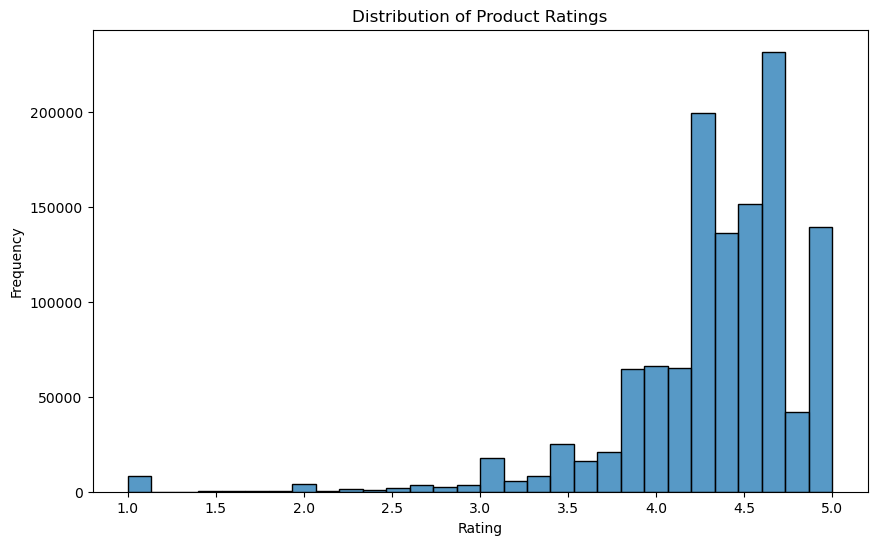

In [81]:
plt.figure(figsize=(10,6))
sns.histplot(df_ratings["stars"], bins=30)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")

plt.show()

The histogram confirms that most ratings are concentrated between 4 and 5 stars, with 4.5–5 stars being the most common range.

#### Conclusion 3: Customer feedback shows a strong positive bias, with most products receiving favorable reviews. This may reflect high satisfaction or a tendency for users to leave positive ratings.